# 6. Pregado e linguado

> **Os dados deste projeto são SIMULADOS** (ver notebook 01). Não são registos de nenhuma exploração.

O pregado (*Scophthalmus maximus*) e o linguado (*Solea senegalensis*) são peixes chatos criados sobretudo em **tanques em terra**, e os dois são produzidos em Portugal. Neste notebook:
1. calibramos o TGC de cada espécie a partir das durações de cultivo publicadas;
2. simulamos um ciclo de engorda e comparamos com outros dados de cultivo;
3. vemos o efeito da temperatura da água.

**Atenção:** ao contrário da dourada (Mayer et al., 2012), para estas espécies **não encontrámos um modelo de crescimento ajustado a dados de explorações comerciais**. Os parâmetros são calibrações e alguns são pressupostos. São os menos seguros do projeto.

In [1]:
import sys
sys.path.append("..")   # para o Python encontrar a pasta src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.growth import PARAMETROS, simular_ciclo, dias_ate_peso, dias_ate_peso_medio

sns.set_theme(style="whitegrid", context="notebook")
CORES = {"pregado": "#9A4632", "linguado": "#4F7A3A"}
NOMES = {"pregado": "Pregado (Scophthalmus maximus)", "linguado": "Linguado (Solea senegalensis)"}
ESPECIES = ["pregado", "linguado"]

## 6.1 Parâmetros e fontes

| Parâmetro | Pregado | Linguado | Fonte |
|---|---|---|---|
| TGC (fase $W^{1/3}$) | 0,00105 | 0,000516 | **Calibração** (ver 6.2) |
| Temperatura base | 0 °C | 0 °C | TGC clássico (Cho, 1992); **pressuposto** |
| Temperatura máxima do modelo | 23 °C | 25 °C | FAO (intervalo extremo do pregado 11–23 °C); Morais et al. (2016) |
| Sobrevivência no ciclo | 85 % | 99 % | **pressuposto** (igual ao robalo); Quental-Ferreira et al. (2010), citado em Morais et al. (2016) |
| FCR | 1,15 | 2,2 | FAO (1,1–1,2); Valente et al. (2011), citado em Morais et al. (2016) |
| Tamanho comercial | 1 kg (vende-se entre 0,7 e 2 kg) | 350 g | FAO |

Usamos o **TGC clássico** (só a fase $W^{1/3}$) com temperatura base de 0 °C, a forma original de Cho (1992), porque não encontrámos uma temperatura mínima de crescimento publicada para estas espécies em engorda. Na dourada e no robalo a base é 12 °C (Mayer et al., 2008).

In [2]:
pd.DataFrame(PARAMETROS).T.loc[ESPECIES]

,nome_cientifico,tgc_1_3,tgc_2_3,temperatura_base,temperatura_maxima,sobrevivencia_ciclo,duracao_ciclo_dias,fcr
pregado,Scophthalmus maximus,0.00105,None,0.0,23.0,0.85,675,1.15
linguado,Solea senegalensis,0.000516,None,0.0,25.0,0.99,517,2.2


## 6.2 Calibração do TGC

Com o TGC clássico, a relação entre o peso inicial $W_i$, o peso final $W_f$ e a soma das temperaturas é:

$$TGC = \frac{W_f^{1/3} - W_i^{1/3}}{\sum T}$$

Para cada espécie usamos a duração de cultivo indicada pela FAO:
- **Pregado:** na pré-engorda passa de 5–10 g a 80–100 g em 4–6 meses; a temperatura ótima para comer é 14–18 °C. Usamos 7,5 g → 90 g em 150 dias a 16 °C.
- **Linguado:** de 5 g a 350 g em 16–18 meses, a 19–21 °C. Usamos 517 dias (17 meses) a 20 °C.

In [3]:
def tgc(peso_inicial, peso_final, dias, temperatura):
    # Coeficiente de crescimento térmico clássico (temperatura base 0 °C)
    return (peso_final ** (1 / 3) - peso_inicial ** (1 / 3)) / (dias * temperatura)

print(f"Pregado:  TGC = {tgc(7.5, 90, 150, 16):.5f}  (no modelo: {PARAMETROS['pregado']['tgc_1_3']})")
print(f"Linguado: TGC = {tgc(5, 350, 517, 20):.6f} (no modelo: {PARAMETROS['linguado']['tgc_1_3']})")

Pregado:  TGC = 0.00105  (no modelo: 0.00105)
Linguado: TGC = 0.000516 (no modelo: 0.000516)


## 6.3 Simulação de um ciclo e comparação com outros dados

Simulamos 5 000 peixes de cada espécie num tanque com temperatura constante: o pregado a 16 °C, a partir de 10 g, e o linguado a 20 °C, a partir de 5 g. Comparamos depois com dados de cultivo que **não** foram usados na calibração.

In [4]:
N_DIAS = 1000
cenarios = {"pregado": {"temperatura": 16, "peso_inicial": 10, "alvo": 1000},
            "linguado": {"temperatura": 20, "peso_inicial": 5, "alvo": 350}}
simulacoes = {}
for especie, cen in cenarios.items():
    simulacoes[especie] = simular_ciclo(especie, n_dias=N_DIAS, n_peixes=5000,
                                        temperatura=np.full(N_DIAS, cen["temperatura"]),
                                        peso_inicial_g=cen["peso_inicial"], semente=42)

resumo = []
for especie, sim in simulacoes.items():
    cen = cenarios[especie]
    dia = dias_ate_peso(sim, cen["alvo"])
    resumo.append({"espécie": especie, "temperatura (°C)": cen["temperatura"],
                   "de (g)": cen["peso_inicial"], "até (g)": cen["alvo"],
                   "dias": dia, "meses": round(dia / 30.4, 1),
                   "sobrevivência (%)": round(sim.loc[dia, "n_peixes"] / 5000 * 100, 1)})
pd.DataFrame(resumo).set_index("espécie")

,temperatura (°C),de (g),até (g),dias,meses,sobrevivência (%)
espécie,,,,,,
pregado,16,10,1000,460,15.1,89.5
linguado,20,5,350,510,16.8,99.1


In [5]:
# Pregado: até 1,25 kg (meio do intervalo 1–1,5 kg de uma exploração em Portugal, 600–750 dias)
print("Pregado de 10 g a 1 250 g:", dias_ate_peso(simulacoes["pregado"], 1250), "dias")

# Linguado: Valente et al. (2011) mediram 180 g -> 323–354 g em 240 dias a 19 °C
linguado_19 = simular_ciclo("linguado", n_dias=400, n_peixes=5000, temperatura=np.full(400, 19.0),
                            peso_inicial_g=180, semente=42)
print(f"Linguado de 180 g ao fim de 240 dias a 19 °C: {linguado_19.loc[240, 'peso_medio_g']:.0f} g")

Pregado de 10 g a 1 250 g: 505 dias


Linguado de 180 g ao fim de 240 dias a 19 °C: 515 g


**Comparação com dados de cultivo:**

| | Modelo | Dados de cultivo |
|---|---|---|
| Pregado, 10 g → 1–1,5 kg | 460 dias até 1 kg; 505 dias até 1,25 kg | 600–750 dias numa exploração em Portugal |
| Linguado, 180 g, 240 dias a 19 °C | 515 g | 323–354 g (Valente et al., 2011) |

Nas duas espécies o modelo **cresce mais depressa nos peixes grandes** do que os dados de cultivo: o pregado chega a 1–1,5 kg cerca de 20–30 % mais cedo, e o linguado de 180 g fica cerca de 50 % mais pesado ao fim de 240 dias. É o mesmo problema que Mayer et al. (2012) encontraram na dourada: o TGC calculado com juvenis sobrestima o crescimento dos peixes maiores, que crescem mais devagar do que a fase $W^{1/3}$ prevê. Como os dois TGC foram calibrados com juvenis (pregado) ou com o ciclo inteiro a partir de 5 g (linguado), as previsões para peixes grandes devem ser lidas como **otimistas**. Um modelo em duas fases, como o da dourada, resolveria isto, mas precisaria de pesagens de uma exploração.

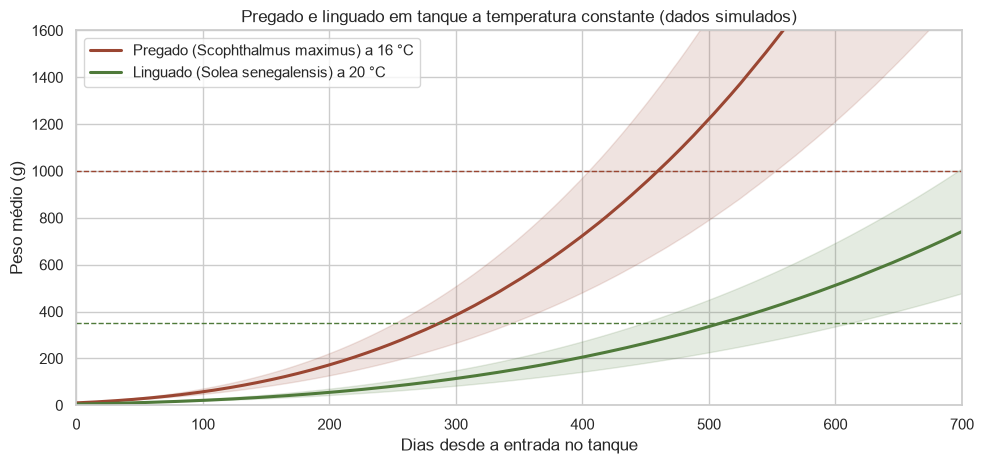

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for especie, sim in simulacoes.items():
    ax.plot(sim["dia"], sim["peso_medio_g"], color=CORES[especie], linewidth=2.2,
            label=f"{NOMES[especie]} a {cenarios[especie]['temperatura']} °C")
    ax.fill_between(sim["dia"], sim["peso_medio_g"] - sim["peso_dp_g"],
                    sim["peso_medio_g"] + sim["peso_dp_g"], color=CORES[especie], alpha=0.15)
    ax.axhline(cenarios[especie]["alvo"], color=CORES[especie], linestyle="--", linewidth=1)
ax.set_xlim(0, 700)
ax.set_ylim(0, 1600)
ax.set_title("Pregado e linguado em tanque a temperatura constante (dados simulados)")
ax.set_xlabel("Dias desde a entrada no tanque")
ax.set_ylabel("Peso médio (g)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("../figures/06_pregado_linguado.png", dpi=150)
plt.show()

## 6.4 Efeito da temperatura

Com o TGC clássico o crescimento é proporcional à temperatura. Calculamos os dias até ao tamanho comercial a várias temperaturas constantes, para um peixe médio (sem variação individual nem mortalidade), até ao limite do modelo de cada espécie.

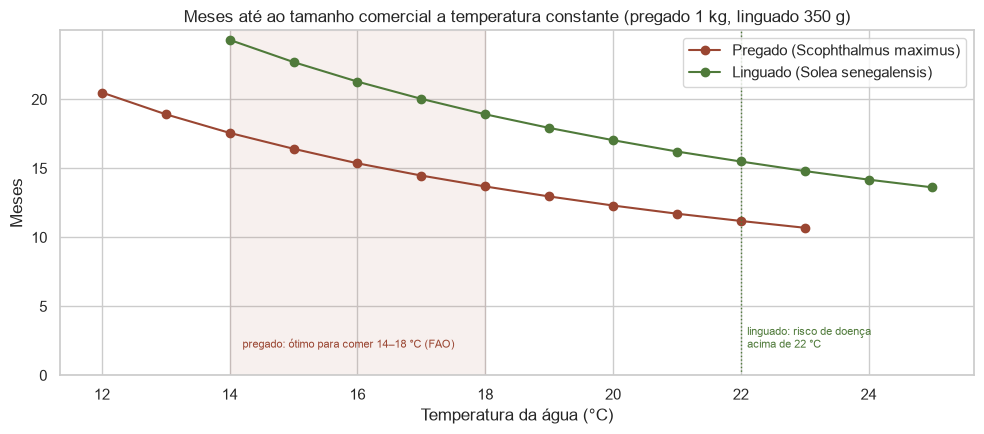

espécie,linguado,pregado
temperatura (°C),,
12.0,NaN,623.0
13.0,NaN,575.0
14.0,739.0,534.0
15.0,690.0,499.0
16.0,647.0,467.0
17.0,609.0,440.0
18.0,575.0,416.0
19.0,545.0,394.0
20.0,518.0,374.0


In [7]:
temperaturas = {"pregado": np.arange(12, 23.5, 1.0), "linguado": np.arange(14, 25.5, 1.0)}
linhas = []
for especie, temps in temperaturas.items():
    cen = cenarios[especie]
    dias = dias_ate_peso_medio(especie, np.repeat(temps[:, None], 2000, axis=1), cen["peso_inicial"], cen["alvo"])
    linhas += [{"espécie": especie, "temperatura (°C)": t, "dias": d} for t, d in zip(temps, dias)]
temperatura_dias = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(10, 4.5))
for especie in ESPECIES:
    d = temperatura_dias[temperatura_dias["espécie"] == especie]
    ax.plot(d["temperatura (°C)"], d["dias"] / 30.4, "o-", color=CORES[especie], label=NOMES[especie])
ax.axvspan(14, 18, color=CORES["pregado"], alpha=0.08)
ax.text(14.2, 2, "pregado: ótimo para comer 14–18 °C (FAO)", fontsize=8, color=CORES["pregado"])
ax.axvline(22, color=CORES["linguado"], linestyle=":", linewidth=1)
ax.text(22.1, 2, "linguado: risco de doença\nacima de 22 °C", fontsize=8, color=CORES["linguado"])
ax.set_title("Meses até ao tamanho comercial a temperatura constante (pregado 1 kg, linguado 350 g)")
ax.set_xlabel("Temperatura da água (°C)")
ax.set_ylabel("Meses")
ax.set_ylim(0, None)
ax.legend()
plt.tight_layout()
plt.show()
temperatura_dias.pivot(index="temperatura (°C)", columns="espécie", values="dias")

**Leitura:**
- Com o TGC clássico, cada grau a mais encurta o ciclo, sem limite: o modelo **não tem temperatura ótima**. Na realidade, o pregado come melhor a 14–18 °C (FAO) e o linguado a cerca de 20 °C, com mais risco de doença acima de 22 °C (Morais et al., 2016). Por isso limitámos o modelo a 23 °C no pregado e a 25 °C no linguado, mas mesmo abaixo desses limites as temperaturas altas são **otimistas**.
- Como a temperatura base é 0 °C, o efeito de cada grau é muito menor do que na dourada (base 12 °C): passar de 16 para 20 °C encurta o ciclo cerca de 20 %, contra cerca de 50 % na dourada (notebook 04). Se a temperatura mínima real de crescimento destas espécies for mais alta, o efeito da temperatura será maior do que o modelo mostra.

## 6.5 Conclusões

1. Com o TGC calibrado, o modelo reproduz as durações de cultivo da FAO: o pregado chega a 1 kg em cerca de 15 meses a 16 °C e o linguado a 350 g em cerca de 17 meses a 20 °C.
2. Comparado com outros dados de cultivo, o modelo é **otimista nos peixes grandes** nas duas espécies, tal como o TGC de uma fase na dourada (Mayer et al., 2012).
3. A temperatura tem menos efeito do que na dourada, por causa da temperatura base de 0 °C (pressuposto).

**Limitações:**
- Não há um modelo de crescimento ajustado a explorações comerciais destas espécies; os TGC são calibrações.
- A temperatura base (0 °C), a sobrevivência do pregado e o preço do juvenil de pregado (na app) são pressupostos.
- O modelo não tem temperatura ótima.
- O linguado tem uma grande variação de tamanhos em cultivo, e as fêmeas crescem mais do que os machos (Morais et al., 2016); o modelo usa a mesma variação individual (15 %) para todas as espécies.

Estas duas espécies não entram nos notebooks 01 a 05, que usam os dados simulados da dourada e do robalo.